In [ ]:
# Run this at the START of every notebook this week
import nltk
nltk.download(["stopwords", "wordnet", "punkt", "punkt_tab"], quiet=True)
print("NLTK data ready!")

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


NLTK data ready!
Using device: cpu


# Week 1

## Day 1

NLP Fundamentals — Turning Words Into Numbers

### Load Real News Data

In [ ]:
# from sklearn.datasets import fetch_20newsgroups
# import pandas as pd

# # Real news articles across 4 different topics
# categories = ["sci.med", "sci.space", "rec.sport.hockey", "talk.politics.guns"]
# news = fetch_20newsgroups(subset="all", categories=categories,
#                           remove=("headers","footers","quotes"))

# print(f"Loaded {len(news.data)} articles across {len(categories)} categories")
# print(f"Categories: {news.target_names}")
# print(f"\nExample article (first 300 chars):")
# print(news.data[0][:300])
# print(f"\nIts category: {news.target_names[news.target[0]]}")

# # Look at the category distribution
# import numpy as np
# unique, counts = np.unique(news.target, return_counts=True)
# for cat_idx, count in zip(unique, counts):
#     print(f"  {news.target_names[cat_idx]:<25}: {count} articles")

!pip install datasets -q

from datasets import load_dataset
import pandas as pd

# Load 20 Newsgroups via Hugging Face instead of sklearn's broken download
hf_20news = load_dataset("SetFit/20_newsgroups")

# Convert to the same style as sklearn's format, filtered to your 4 categories
categories = ["sci.med", "sci.space", "rec.sport.hockey", "talk.politics.guns"]

train_df = pd.DataFrame(hf_20news["train"])
filtered_df = train_df[train_df["label_text"].isin(categories)].reset_index(drop=True)

print(f"Loaded {len(filtered_df)} articles across {filtered_df['label_text'].nunique()} categories")
print(filtered_df["label_text"].value_counts())

# Recreate the same variables your existing code expects
news_data = filtered_df["text"].tolist()
news_target = filtered_df["label_text"].astype("category").cat.codes.tolist()
news_target_names = sorted(filtered_df["label_text"].unique())

print(f"\nExample article:")
print(news_data[0][:300])

README.md:   0%|          | 0.00/734 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl: reconstructing file:   0%|          |  0.00B / 14.8MB            

train.jsonl: downloading bytes:           |  0.00B            

test.jsonl: reconstructing file:   0%|          |  0.00B / 8.91MB            

test.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11314 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7532 [00:00<?, ? examples/s]

Loaded 2333 articles across 4 categories
label_text
rec.sport.hockey      600
sci.med               594
sci.space             593
talk.politics.guns    546
Name: count, dtype: int64

Example article:
From article <C5owCB.n3p@world.std.com>, by tombaker@world.std.com (Tom A Baker):


My understanding is that the 'expected errors' are basically
known bugs in the warning system software - things are checked
that don't have the right values in yet because they aren't
set till after launch, and suchl


### The Text Cleaning Pipeline

### FROM RAW TEXT TO NUMBERS -- The Cleaning Pipeline
======================================================

Raw text:
  "The Runners are RUNNING quickly!! They've run 5 miles..."

STEP 1: LOWERCASE
  "the runners are running quickly!! they've run 5 miles..."
  WHY: "Dog" and "dog" should be treated as the SAME word

STEP 2: REMOVE PUNCTUATION/NUMBERS
  "the runners are running quickly theyve run miles"
  WHY: Punctuation rarely carries meaning for basic text tasks

STEP 3: TOKENIZE (split into individual words)
  ["the", "runners", "are", "running", "quickly", "theyve", "run", "miles"]
  WHY: We need individual WORDS as our basic units

STEP 4: REMOVE STOP WORDS (the, is, are, a, an...)
  ["runners", "running", "quickly", "theyve", "run", "miles"]
  WHY: These words appear in EVERY sentence -- they carry no
  distinguishing information about what makes THIS text unique

STEP 5: LEMMATIZE (reduce to root/dictionary form)
  ["runner", "run", "quickly", "theyve", "run", "mile"]
  WHY: "Runners", "running", "run" are all the SAME core concept.
  ANALOGY: Just like grouping "walked/walking/walks" all under
  the single concept "walk" -- reduces vocabulary size dramatically

RESULT: clean, standardised tokens ready to be counted/converted
to numbers

### BAG OF WORDS -- Counting Words, Ignoring Order
======================================================

ANALOGY: Dumping every word from a document into a jar and
just counting how many times each word appears -- completely
ignoring what ORDER they originally appeared in.

Document 1: "I love machine learning"
Document 2: "Machine learning is great"
Document 3: "I hate spam emails"

VOCABULARY (all unique words across all documents):
  [i, love, machine, learning, is, great, hate, spam, emails]

Document 1 as a vector (count of each vocabulary word):
  [1, 1, 1, 1, 0, 0, 0, 0, 0]
   i  love mach learn is  great hate spam email

Document 2 as a vector:
  [0, 0, 1, 1, 1, 1, 0, 0, 0]

Document 3 as a vector:
  [1, 0, 0, 0, 0, 0, 1, 1, 1]

Now EVERY document is a row of NUMBERS -- ready for ANY of our
Week 3 classifiers (Logistic Regression, Naive Bayes, etc.)!

LIMITATION: "Bag" of words -- throws away ALL word order.
"Dog bites man" and "Man bites dog" produce IDENTICAL vectors.
This is a real weakness we'll address with RNNs later this week.

In [ ]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))

def clean_text(text):
    """The complete text cleaning pipeline, step by step"""
    # STEP 1: lowercase
    text = text.lower()
    # STEP 2: remove punctuation and numbers (keep only letters + spaces)
    text = re.sub(r"[^a-z\s]", "", text)
    # STEP 3: tokenize
    tokens = word_tokenize(text)
    # STEP 4: remove stop words + very short tokens
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]
    # STEP 5: lemmatize
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return " ".join(tokens)

# Demonstrate on ONE example, step by step
sample = news_data[0][:300]
print("ORIGINAL:")
print(sample)
print("\nCLEANED:")
print(clean_text(sample))

# Now clean the ENTIRE dataset
print(f"\nCleaning all {len(news_data)} articles...")
cleaned_texts = [clean_text(doc) for doc in news_data]
print(f"Done! Example cleaned article:\n{cleaned_texts[0][:200]}")

print(f"""
NOTICE: The cleaned text has fewer, more meaningful words.
Stop words like "the", "is", "and" are GONE.
Words are reduced to their root form (lemmatized).
This is now ready to be converted into NUMBERS.
""")

ORIGINAL:
From article <C5owCB.n3p@world.std.com>, by tombaker@world.std.com (Tom A Baker):


My understanding is that the 'expected errors' are basically
known bugs in the warning system software - things are checked
that don't have the right values in yet because they aren't
set till after launch, and suchl

CLEANED:
article cowcbnpworldstdcom tombakerworldstdcom tom baker understanding expected error basically known bug warning system software thing checked dont right value yet arent set till launch suchl

Cleaning all 2333 articles...
Done! Example cleaned article:
article cowcbnpworldstdcom tombakerworldstdcom tom baker understanding expected error basically known bug warning system software thing checked dont right value yet arent set till launch suchlike rath

NOTICE: The cleaned text has fewer, more meaningful words.
Stop words like "the", "is", "and" are GONE.
Words are reduced to their root form (lemmatized).
This is now ready to be converted into NUMBERS.



### Bag of Words in Practice

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

# Small demo first, to see the actual vectors
demo_docs = ["I love machine learning",
             "Machine learning is great",
             "I hate spam emails"]

vectorizer_demo = CountVectorizer()
demo_vectors = vectorizer_demo.fit_transform(demo_docs)

print("Vocabulary (all unique words found):")
print(vectorizer_demo.get_feature_names_out())

print("\nDocument vectors (rows=documents, columns=word counts):")
demo_df = pd.DataFrame(demo_vectors.toarray(),
                       columns=vectorizer_demo.get_feature_names_out())
print(demo_df)

# Now apply to our REAL news dataset
print("\n" + "="*55)
print("BAG OF WORDS ON REAL NEWS DATA")
print("="*55)

count_vectorizer = CountVectorizer(max_features=2000)   # top 2000 most common words
X_bow = count_vectorizer.fit_transform(cleaned_texts)

print(f"Bag of Words matrix shape: {X_bow.shape}")
print(f"  -> {X_bow.shape[0]} articles, {X_bow.shape[1]} vocabulary words")
print(f"\nMost common words in vocabulary:")
print(count_vectorizer.get_feature_names_out()[:20])

Vocabulary (all unique words found):
['emails' 'great' 'hate' 'is' 'learning' 'love' 'machine' 'spam']

Document vectors (rows=documents, columns=word counts):
   emails  great  hate  is  learning  love  machine  spam
0       0      0     0   0         1     1        1     0
1       0      1     0   1         1     0        1     0
2       1      0     1   0         0     0        0     1

BAG OF WORDS ON REAL NEWS DATA
Bag of Words matrix shape: (2333, 2000)
  -> 2333 articles, 2000 vocabulary words

Most common words in vocabulary:
['abc' 'ability' 'able' 'absolutely' 'abuse' 'acceleration' 'accept'
 'accepted' 'access' 'accident' 'accidental' 'according' 'account'
 'accurate' 'acid' 'acquired' 'acronym' 'across' 'act' 'action']


### TF-IDF + First Text Classifier

TF - Term Frequency

IDF - Inverse Document Frequency

PROBLEM WITH PLAIN BAG OF WORDS: the word "the" appears constantly
in EVERY document -- it gets a huge count, but tells us NOTHING
useful about what makes any one document special or different.

TF (Term Frequency): how often does this word appear in THIS document?
IDF (Inverse Document Frequency): how RARE is this word across
  ALL documents? (Rare across all docs = high IDF = more special)

TF-IDF score = TF x IDF

  HIGH score: word appears OFTEN in this doc, but RARELY elsewhere

              -> this word is DISTINCTIVE, important for this document

  LOW score:  word appears in almost every document ("the", "is")
  
              -> not useful for telling documents apart

Words like "neural" or "medicine" in a specific article get HIGH
TF-IDF scores -- they're doing real WORK to characterise that text.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

tfidf_vectorizer = TfidfVectorizer(max_features=2000, ngram_range=(1,2))
X_tfidf = tfidf_vectorizer.fit_transform(cleaned_texts)
y = news_target

print(f"TF-IDF matrix shape: {X_tfidf.shape}")

# Compare a few articles' top TF-IDF words
feature_names = tfidf_vectorizer.get_feature_names_out()
doc_idx = 0
tfidf_scores = X_tfidf[doc_idx].toarray()[0]
top_indices  = tfidf_scores.argsort()[-5:][::-1]
print(f"\nTop 5 distinguishing words for article 0 "
      f"(category: {news_target_names[y[doc_idx]]}):")
for idx in top_indices:
    print(f"  {feature_names[idx]:<20}: {tfidf_scores[idx]:.3f}")

# Train/test split -- straight from Week 3 skills!
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y, test_size=0.2, random_state=42, stratify=y
)

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_pred  = nb_model.predict(X_test)
print(f"\nNaive Bayes on TF-IDF: Accuracy = {accuracy_score(y_test, nb_pred):.4f}")

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
lr_pred  = lr_model.predict(X_test)
print(f"Logistic Regression on TF-IDF: Accuracy = {accuracy_score(y_test, lr_pred):.4f}")

print(f"\nDetailed report (Logistic Regression):")
print(classification_report(y_test, lr_pred, target_names=news_target_names))

TF-IDF matrix shape: (2333, 2000)

Top 5 distinguishing words for article 0 (category: sci.space):
  crew                : 0.229
  code                : 0.221
  error               : 0.217
  tom                 : 0.216

Naive Bayes on TF-IDF: Accuracy = 0.8801
Logistic Regression on TF-IDF: Accuracy = 0.8715

Detailed report (Logistic Regression):
                    precision    recall  f1-score   support

  rec.sport.hockey       0.96      0.89      0.92       120
           sci.med       0.93      0.87      0.90       119
         sci.space       0.75      0.89      0.82       119
talk.politics.guns       0.88      0.83      0.85       109

          accuracy                           0.87       467
         macro avg       0.88      0.87      0.87       467
      weighted avg       0.88      0.87      0.87       467



## Day 2

"Teaching a machine that 'king' and 'queen' are related"


### Load Pretrained Word Embeddings

In [ ]:
!pip install gensim -q

import gensim.downloader as api
import numpy as np

print("Downloading pretrained word embeddings (trained on Google News,")
print("100 billion words) -- this may take a minute the first time...")

# Load a smaller, faster pretrained embedding model for classroom use
word_vectors = api.load("glove-wiki-gigaword-100")   # 100-dimensional vectors

print(f"\nLoaded! Vocabulary size: {len(word_vectors):,} words")
print(f"Each word is represented as a vector of {word_vectors.vector_size} numbers")

# Look at one word's actual embedding vector
king_vector = word_vectors["king"]
print(f"\n'king' embedding (first 10 of {len(king_vector)} numbers):")
print(king_vector[:10])
print(f"\nThis 100-number vector is the model's 'address' for the")
print(f"word king in meaning-space. It looks like meaningless numbers")
print(f"to us, but it captures rich semantic information.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 21.1 MB/s eta 0:00:00
100 billion words) -- this may take a minute the first time...
[==================================================] 100.0% 128.1/128.1MB downloaded

Loaded! Vocabulary size: 400,000 words
Each word is represented as a vector of 100 numbers

'king' embedding (first 10 of 100 numbers):
[-0.32307 -0.87616  0.21977  0.25268  0.22976  0.7388  -0.37954 -0.35307
 -0.84369 -1.1113 ]

This 100-number vector is the model's 'address' for the
word king in meaning-space. It looks like meaningless numbers
to us, but it captures rich semantic information.


### Word Similarity

In [ ]:
print("MOST SIMILAR WORDS -- finding nearby points in embedding space")
print("="*55)

for word in ["king", "happy", "computer"]:
    similar = word_vectors.most_similar(word, topn=5)
    print(f"\nWords most similar to '{word}':")
    for similar_word, score in similar:
        print(f"  {similar_word:<15}: similarity = {score:.3f}")

# Measure similarity between SPECIFIC pairs
print("\n" + "="*55)
print("DIRECT SIMILARITY COMPARISONS")
print("="*55)

pairs = [
    ("happy", "joyful"),
    ("happy", "sad"),
    ("king", "queen"),
    ("king", "bicycle"),
    ("dog", "puppy"),
]
for word1, word2 in pairs:
    similarity = word_vectors.similarity(word1, word2)
    print(f"  similarity('{word1}', '{word2}') = {similarity:.3f}")

print(f"\nNotice: related words score HIGH (close to 1.0).")
print(f"Unrelated words score LOW or even negative.")
print(f"This similarity score is simply the geometric closeness")
print(f"of the two words' positions in the 100-dimensional space.")

MOST SIMILAR WORDS -- finding nearby points in embedding space

Words most similar to 'king':
  prince         : similarity = 0.768
  queen          : similarity = 0.751
  son            : similarity = 0.702
  brother        : similarity = 0.699
  monarch        : similarity = 0.698

Words most similar to 'happy':
  'm             : similarity = 0.841
  feel           : similarity = 0.813
  're            : similarity = 0.805
  i              : similarity = 0.794
  'll            : similarity = 0.792

Words most similar to 'computer':
  computers      : similarity = 0.875
  software       : similarity = 0.837
  technology     : similarity = 0.764
  pc             : similarity = 0.737
  hardware       : similarity = 0.729

DIRECT SIMILARITY COMPARISONS
  similarity('happy', 'joyful') = 0.526
  similarity('happy', 'sad') = 0.680
  similarity('king', 'queen') = 0.751
  similarity('king', 'bicycle') = 0.096
  similarity('dog', 'puppy') = 0.724

Notice: related words score HIGH (close to 1.

### Word Arithmetic — The Famous Example

In [ ]:
print("WORD ARITHMETIC -- Capturing RELATIONSHIPS, Not Just Meaning")
print("="*55)

# The famous example: king - man + woman = ?
result = word_vectors.most_similar(
    positive=["king", "woman"],
    negative=["man"],
    topn=3
)
print(f"\nking - man + woman = ?")
for word, score in result:
    print(f"  {word:<15}: {score:.3f}")

# Try more relationship examples
print(f"\nparis - france + italy = ?")
result2 = word_vectors.most_similar(positive=["paris","italy"], negative=["france"], topn=3)
for word, score in result2:
    print(f"  {word:<15}: {score:.3f}")

print(f"\nwalking - walk + swim = ?")
result3 = word_vectors.most_similar(positive=["walking","swim"], negative=["walk"], topn=3)
for word, score in result3:
    print(f"  {word:<15}: {score:.3f}")

print(f"""
This works because embeddings capture RELATIONSHIPS as DIRECTIONS
in space. The direction from "man" to "king" (adding "royalty/male
ruler") is roughly the SAME direction as from "woman" to "queen".

The model was NEVER explicitly told "king is to man as queen is to
woman" -- it discovered this relationship purely from analysing
how these words are USED in millions of real sentences.
""")

WORD ARITHMETIC -- Capturing RELATIONSHIPS, Not Just Meaning

king - man + woman = ?
  queen          : 0.770
  monarch        : 0.684
  throne         : 0.676

paris - france + italy = ?
  rome           : 0.819
  milan          : 0.738
  naples         : 0.712

walking - walk + swim = ?
  swimming       : 0.801
  surfing        : 0.660
  swam           : 0.645

This works because embeddings capture RELATIONSHIPS as DIRECTIONS
in space. The direction from "man" to "king" (adding "royalty/male
ruler") is roughly the SAME direction as from "woman" to "queen".

The model was NEVER explicitly told "king is to man as queen is to
woman" -- it discovered this relationship purely from analysing
how these words are USED in millions of real sentences.



### Visualise Embeddings in 2D

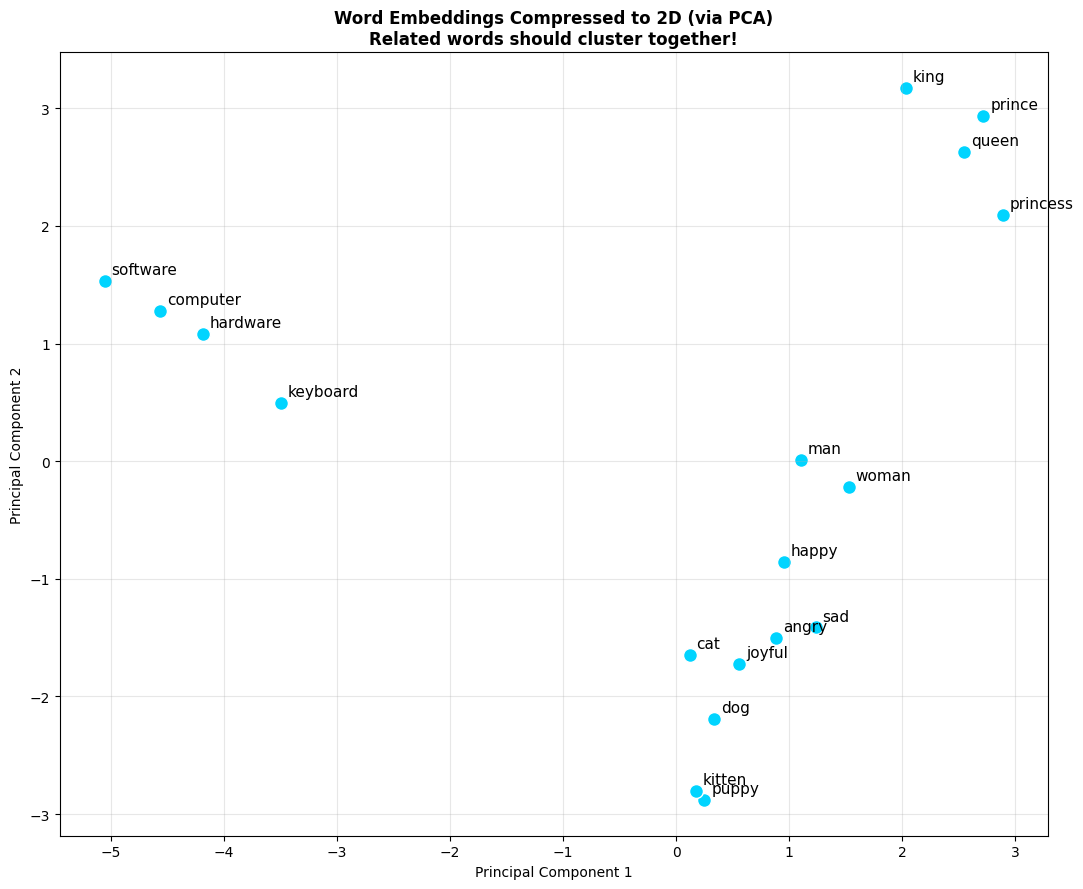

Notice the natural CLUSTERS: royalty words together, emotion
words together, animal words together, tech words together --
all emerging PURELY from the embedding's learned structure,
with no explicit categories ever provided to the model.


In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Embeddings live in 100 dimensions -- use PCA (Week 4!) to compress to 2D
words_to_plot = ["king", "queen", "man", "woman", "prince", "princess",
                  "happy", "sad", "joyful", "angry",
                  "dog", "cat", "puppy", "kitten",
                  "computer", "keyboard", "software", "hardware"]

vectors = np.array([word_vectors[w] for w in words_to_plot])

pca = PCA(n_components=2)
vectors_2d = pca.fit_transform(vectors)

plt.figure(figsize=(11, 9))
plt.scatter(vectors_2d[:,0], vectors_2d[:,1], s=100, color="#00d4ff", edgecolor="white")
for i, word in enumerate(words_to_plot):
    plt.annotate(word, (vectors_2d[i,0], vectors_2d[i,1]),
                fontsize=11, xytext=(5,5), textcoords="offset points")
plt.title("Word Embeddings Compressed to 2D (via PCA)\n"
          "Related words should cluster together!", fontweight="bold")
plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

print("Notice the natural CLUSTERS: royalty words together, emotion")
print("words together, animal words together, tech words together --")
print("all emerging PURELY from the embedding's learned structure,")
print("with no explicit categories ever provided to the model.")

## Day 3

RNN/LSTM — Neural Networks That Remember

### Load Real IMDB Movie Review Data

In [ ]:
from datasets import load_dataset
import pandas as pd

print("Loading real IMDB movie reviews (25,000 reviews, labeled")
print("positive/negative)...")

imdb = load_dataset("stanfordnlp/imdb")
train_data = imdb["train"].shuffle(seed=42).select(range(2000))   # subset for speed
test_data  = imdb["test"].shuffle(seed=42).select(range(500))

print(f"\nTraining reviews: {len(train_data)}")
print(f"Test reviews:      {len(test_data)}")

print(f"\nExample review (positive={train_data[0]['label']==1}):")
print(train_data[0]["text"][:300])

labels_train = [ex["label"] for ex in train_data]
print(f"\nLabel distribution: {sum(labels_train)} positive, "
      f"{len(labels_train)-sum(labels_train)} negative")

Loading real IMDB movie reviews (25,000 reviews, labeled
positive/negative)...


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]


Training reviews: 2000
Test reviews:      500

Example review (positive=True):
There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot 

Label distribution: 1000 positive, 1000 negative


### Build Vocabulary + Convert to Sequences

In [ ]:
import re
from collections import Counter
import torch
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader
import random

def simple_clean(text):
    text = text.lower()
    text = re.sub(r"<br\s*/?>", " ", text)   # remove HTML line breaks
    text = re.sub(r"[^a-z\s]", "", text)
    return text.split()

# Build vocabulary from training data
print("Building vocabulary from training reviews...")
all_words = Counter()
for ex in train_data:
    all_words.update(simple_clean(ex["text"]))

VOCAB_SIZE = 5000
most_common = all_words.most_common(VOCAB_SIZE - 2)   # reserve 2 special tokens
vocab = {"<PAD>": 0, "<UNK>": 1}
for word, count in most_common:
    vocab[word] = len(vocab)

print(list(vocab.values())[:10])


print(f"Vocabulary size: {len(vocab)}")
print(f"Most common words: {list(vocab.keys())[2:12]}")

def text_to_sequence(text, max_len=200):
    """Convert text to a fixed-length sequence of vocabulary IDs"""
    words = simple_clean(text)
    ids   = [vocab.get(w, vocab["<UNK>"]) for w in words[:max_len]]
    ids   = ids + [vocab["<PAD>"]] * (max_len - len(ids))   # pad to fixed length
    return ids[:max_len]

# Demonstrate the conversion
example_seq = text_to_sequence(train_data[0]["text"])
print(f"\nExample review converted to sequence (first 20 IDs):")
print(example_seq[:20])
print(f"\nEach number is a word's ID in our vocabulary --")
print(f"this is the FINAL step turning text into numbers a network can process.")

def set_seed(seed=42):
    random.seed(seed)                      # Python's built-in random module
    np.random.seed(seed)                   # NumPy's random module
    torch.manual_seed(seed)                # PyTorch's CPU random number generator
    torch.cuda.manual_seed_all(seed)       # PyTorch's GPU random number generator
    torch.backends.cudnn.deterministic = True   # force deterministic GPU ops
    torch.backends.cudnn.benchmark = False

set_seed(42)   # call this BEFORE creating your model or DataLoaders

class IMDBDataset(Dataset):
    def __init__(self, hf_dataset, max_len=200):
        self.texts  = [text_to_sequence(ex["text"], max_len) for ex in hf_dataset]
        self.labels = [ex["label"] for ex in hf_dataset]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return torch.tensor(self.texts[idx]), torch.tensor(self.labels[idx])

train_dataset = IMDBDataset(train_data)
test_dataset  = IMDBDataset(test_data)
train_loader  = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader   = DataLoader(test_dataset,  batch_size=32, shuffle=False)

print(f"\nDataLoaders ready. Batch example shape:")
sample_batch, sample_labels = next(iter(train_loader))
print(f"  Text batch: {sample_batch.shape} (32 reviews, 200 words each)")
print(f"  Labels:     {sample_labels.shape}")

Building vocabulary from training reviews...
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Vocabulary size: 5000
Most common words: ['the', 'and', 'a', 'of', 'to', 'is', 'in', 'it', 'i', 'this']

Example review converted to sequence (first 20 IDs):
[47, 7, 59, 1, 30, 31, 188, 1, 3, 1, 18, 2, 183, 12, 198, 22, 533, 194, 40, 944]

Each number is a word's ID in our vocabulary --
this is the FINAL step turning text into numbers a network can process.

DataLoaders ready. Batch example shape:
  Text batch: torch.Size([32, 200]) (32 reviews, 200 words each)
  Labels:     torch.Size([32])


### Build an LSTM Sentiment Classifier

In [ ]:
import torch.nn as nn

class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, num_layers=1):
        super().__init__()
        # STEP 1: Embedding layer -- turns word IDs into meaningful vectors
        # (the network LEARNS these embeddings during training, from scratch)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        # STEP 2: LSTM layer -- processes the sequence, building memory
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers,
                            batch_first=True, bidirectional=True, dropout=0.3)

        # STEP 3: Final classification layer
        self.fc      = nn.Linear(hidden_dim * 2, 1)   # *2 because bidirectional
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        embedded        = self.embedding(x)              # (batch, seq_len, embed_dim)
        lstm_out, (h_n, c_n) = self.lstm(embedded)        # process the sequence
        # Combine the final hidden states from BOTH directions
        final_hidden = torch.cat((h_n[-2], h_n[-1]), dim=1)
        output       = self.fc(self.dropout(final_hidden))
        return output.squeeze(1)

model = SentimentLSTM(vocab_size=len(vocab)).to(device)
print(model)
total_params = sum(p.numel() for p in model.parameters())
print(f"\nTotal parameters: {total_params:,}")

print(f"""
ARCHITECTURE WALKTHROUGH:
  1. Embedding: 200 word IDs -> 200 x 64-dimensional vectors
     (the network LEARNS its own embeddings here, unlike yesterday's
      pretrained GloVe -- both approaches are valid!)
  2. LSTM: processes all 200 word-vectors IN SEQUENCE, building memory
  3. Final hidden state: a summary of the ENTIRE review's sentiment
  4. Linear layer: converts that summary into 1 number (positive/negative)
""")

SentimentLSTM(
  (embedding): Embedding(5000, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True, dropout=0.3, bidirectional=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
)

Total parameters: 386,689

ARCHITECTURE WALKTHROUGH:
  1. Embedding: 200 word IDs -> 200 x 64-dimensional vectors
     (the network LEARNS its own embeddings here, unlike yesterday's
      pretrained GloVe -- both approaches are valid!)
  2. LSTM: processes all 200 word-vectors IN SEQUENCE, building memory
  3. Final hidden state: a summary of the ENTIRE review's sentiment
  4. Linear layer: converts that summary into 1 number (positive/negative)



/usr/local/lib/python3.12/dist-packages/torch/nn/modules/rnn.py:1013: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.3 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)


### Train on Real Movie Reviews

Training LSTM Sentiment Classifier on real IMDB reviews...
Epoch 1/5 | Loss: 0.6950 | Train: 48.55% | Test: 50.80%
Epoch 2/5 | Loss: 0.6805 | Train: 57.45% | Test: 52.00%
Epoch 3/5 | Loss: 0.6528 | Train: 62.80% | Test: 54.60%
Epoch 4/5 | Loss: 0.5938 | Train: 69.00% | Test: 59.40%
Epoch 5/5 | Loss: 0.5114 | Train: 75.60% | Test: 61.20%


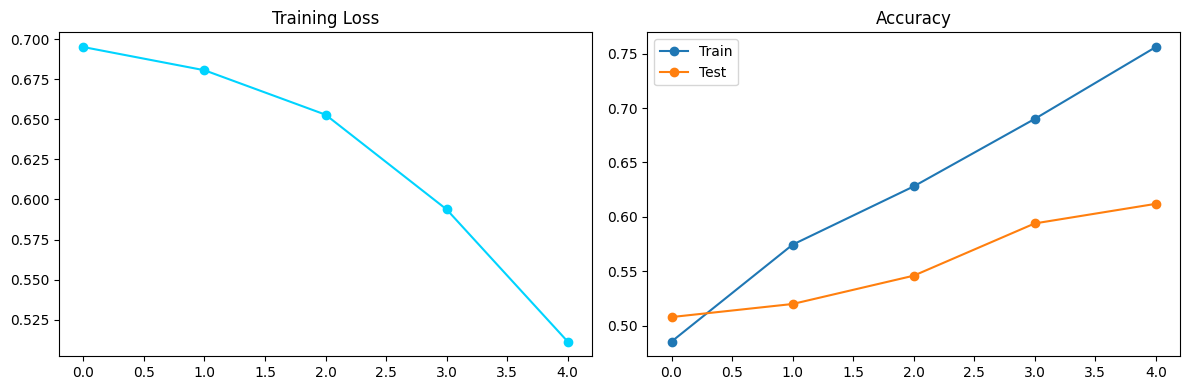


Final test accuracy: 61.20%
The LSTM learned to detect sentiment by processing reviews
WORD BY WORD, building up understanding through its memory --
exactly like the archery-style backpropagation training from Week 5!


In [ ]:
import torch.optim as optim

criterion = nn.BCEWithLogitsLoss()   # Binary Cross Entropy for 2-class sentiment
optimizer = optim.Adam(model.parameters(), lr=0.001)

def train_epoch_lstm(model, loader):
    model.train()
    total_loss, correct = 0, 0
    for texts, labels in loader:
        texts, labels = texts.to(device), labels.float().to(device)
        outputs = model(texts)
        loss    = criterion(outputs, labels)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        total_loss += loss.item()
        preds       = (torch.sigmoid(outputs) > 0.5).float()
        correct    += (preds == labels).sum().item()
    return total_loss/len(loader), correct/len(loader.dataset)

def evaluate_lstm(model, loader):
    model.eval()
    correct = 0
    with torch.no_grad():
        for texts, labels in loader:
            texts, labels = texts.to(device), labels.float().to(device)
            preds   = (torch.sigmoid(model(texts)) > 0.5).float()
            correct += (preds == labels).sum().item()
    return correct/len(loader.dataset)

print("Training LSTM Sentiment Classifier on real IMDB reviews...")
print("="*55)
history = {"loss":[], "train_acc":[], "test_acc":[]}
for epoch in range(5):
    loss, tr_acc = train_epoch_lstm(model, train_loader)
    te_acc       = evaluate_lstm(model, test_loader)
    history["loss"].append(loss); history["train_acc"].append(tr_acc); history["test_acc"].append(te_acc)
    print(f"Epoch {epoch+1}/5 | Loss: {loss:.4f} | Train: {tr_acc:.2%} | Test: {te_acc:.2%}")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1,2, figsize=(12,4))
axes[0].plot(history["loss"], "o-", color="#00d4ff"); axes[0].set_title("Training Loss")
axes[1].plot(history["train_acc"],"o-",label="Train"); axes[1].plot(history["test_acc"],"o-",label="Test")
axes[1].set_title("Accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"\nFinal test accuracy: {history['test_acc'][-1]:.2%}")
print(f"The LSTM learned to detect sentiment by processing reviews")
print(f"WORD BY WORD, building up understanding through its memory --")
print(f"exactly like the archery-style backpropagation training from Week 5!")

## Day 4
The Attention Mechanism — The Bridge to Transformers

### Attention Mechanism From Scratch

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# A minimal, from-scratch attention layer to see EXACTLY what happens
class SimpleAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        # A tiny network that learns to score each word's relevance
        self.attention_score = nn.Linear(hidden_dim, 1)

    def forward(self, lstm_outputs):
        # lstm_outputs shape: (batch, seq_len, hidden_dim)
        # STEP 1: calculate a raw relevance score for EVERY word
        raw_scores = self.attention_score(lstm_outputs)   # (batch, seq_len, 1)

        # STEP 2: softmax -- convert to probabilities summing to 1
        attention_weights = F.softmax(raw_scores, dim=1)   # (batch, seq_len, 1)

        # STEP 3: weighted sum -- combine all words using their weights
        context = torch.sum(attention_weights * lstm_outputs, dim=1)

        return context, attention_weights.squeeze(-1)

# Demonstrate with fake data
demo_lstm_outputs = torch.randn(1, 8, 16)   # 1 sentence, 8 words, 16-dim hidden state
attention_layer   = SimpleAttention(hidden_dim=16)
context, weights  = attention_layer(demo_lstm_outputs)

words = ["The", "acting", "was", "fantastic", "but", "plot", "was", "boring"]
print("Attention weights for each word (learned randomly here, untrained):")
for word, w in zip(words, weights[0].detach().numpy()):
    bar = "#" * int(w * 100)
    print(f"  {word:<12}: {w:.4f}  {bar}")

print(f"\nSum of all weights: {weights[0].sum().item():.4f} (should be ~1.0)")
print(f"\nThis is UNTRAINED, so weights are essentially random right now.")
print(f"After training, the model would LEARN to assign high weights")
print(f"to genuinely important words like 'fantastic' and 'boring'.")

Attention weights for each word (learned randomly here, untrained):
  The         : 0.0621  ######
  acting      : 0.0517  #####
  was         : 0.1354  #############
  fantastic   : 0.0683  ######
  but         : 0.2893  ############################
  plot        : 0.1651  ################
  was         : 0.1301  #############
  boring      : 0.0981  #########

Sum of all weights: 1.0000 (should be ~1.0)

This is UNTRAINED, so weights are essentially random right now.
After training, the model would LEARN to assign high weights
to genuinely important words like 'fantastic' and 'boring'.


### Visualise Attention Weights

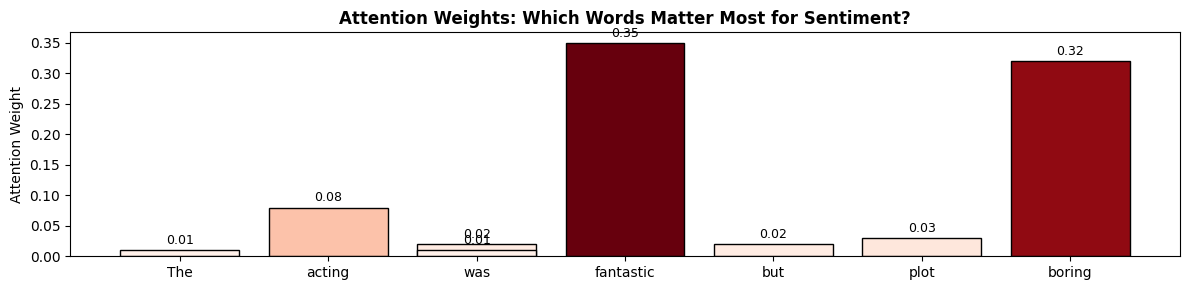

Notice how 'fantastic' and 'boring' receive the HIGHEST attention
(darkest red, tallest bars) -- these are genuinely the words that
determine sentiment. Meanwhile 'the', 'was', 'but' receive minimal
attention -- they're grammatically necessary but don't carry
sentiment information.

THIS IS EXACTLY HOW MODERN AI EXPLAINS ITSELF:
When you ask ChatGPT/Claude a question, internally, attention
mechanisms are highlighting WHICH parts of your question and
conversation history matter most for generating each part of
the response -- at massive scale, with many attention "heads"
each focusing on different types of relationships simultaneously.



In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Simulate what TRAINED attention weights might look like
# (illustrative -- shows what the model WOULD learn with real training)
words_example  = ["The", "acting", "was", "fantastic", "but", "plot", "was", "boring"]
trained_weights = [0.01, 0.08, 0.02, 0.35, 0.02, 0.03, 0.01, 0.32]   # illustrative

fig, ax = plt.subplots(figsize=(12, 3))
colors = plt.cm.Reds(np.array(trained_weights) / max(trained_weights))
bars = ax.bar(words_example, trained_weights, color=colors, edgecolor="black")
ax.set_title("Attention Weights: Which Words Matter Most for Sentiment?",
             fontweight="bold")
ax.set_ylabel("Attention Weight")
for bar, w in zip(bars, trained_weights):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
            f"{w:.2f}", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

print("Notice how 'fantastic' and 'boring' receive the HIGHEST attention")
print("(darkest red, tallest bars) -- these are genuinely the words that")
print("determine sentiment. Meanwhile 'the', 'was', 'but' receive minimal")
print("attention -- they're grammatically necessary but don't carry")
print("sentiment information.")

print(f"""
THIS IS EXACTLY HOW MODERN AI EXPLAINS ITSELF:
When you ask ChatGPT/Claude a question, internally, attention
mechanisms are highlighting WHICH parts of your question and
conversation history matter most for generating each part of
the response -- at massive scale, with many attention "heads"
each focusing on different types of relationships simultaneously.
""")

### Add Attention to Our Sentiment Model

In [ ]:
class AttentionSentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm      = nn.LSTM(embed_dim, hidden_dim, batch_first=True,
                                 bidirectional=True, dropout=0.3)
        self.attention = SimpleAttention(hidden_dim * 2)   # *2 for bidirectional
        self.fc        = nn.Linear(hidden_dim * 2, 1)
        self.dropout   = nn.Dropout(0.3)

    def forward(self, x):
        embedded            = self.embedding(x)
        lstm_out, _          = self.lstm(embedded)          # ALL word outputs, not just final!
        context, attn_weights = self.attention(lstm_out)     # weighted combination
        output               = self.fc(self.dropout(context))
        return output.squeeze(1), attn_weights

print("KEY DIFFERENCE from yesterday's model:")
print("Yesterday: only used the FINAL hidden state (information bottleneck)")
print("Today: uses ALL word outputs, weighted by learned attention")
print("       -- the model can look back at ANY word when deciding\n")

attn_model = AttentionSentimentLSTM(vocab_size=len(vocab)).to(device)
total_params = sum(p.numel() for p in attn_model.parameters())
print(f"Total parameters: {total_params:,}")

KEY DIFFERENCE from yesterday's model:
Yesterday: only used the FINAL hidden state (information bottleneck)
Today: uses ALL word outputs, weighted by learned attention
       -- the model can look back at ANY word when deciding

Total parameters: 386,818


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/rnn.py:1013: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.3 and num_layers=1
  super().__init__("LSTM", *args, **kwargs)


### Train and Compare

In [ ]:
import torch.optim as optim

criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(attn_model.parameters(), lr=0.001)

def train_epoch_attn(model, loader):
    model.train()
    total_loss, correct = 0, 0
    for texts, labels in loader:
        texts, labels = texts.to(device), labels.float().to(device)
        outputs, _ = model(texts)
        loss = criterion(outputs, labels)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        total_loss += loss.item()
        preds = (torch.sigmoid(outputs) > 0.5).float()
        correct += (preds == labels).sum().item()
    return total_loss/len(loader), correct/len(loader.dataset)

def evaluate_attn(model, loader):
    model.eval()
    correct = 0
    with torch.no_grad():
        for texts, labels in loader:
            texts, labels = texts.to(device), labels.float().to(device)
            outputs, _ = model(texts)
            preds = (torch.sigmoid(outputs) > 0.5).float()
            correct += (preds == labels).sum().item()
    return correct/len(loader.dataset)

print("Training Attention-Enhanced LSTM...")
print("="*55)
for epoch in range(5):
    loss, tr_acc = train_epoch_attn(attn_model, train_loader)
    te_acc       = evaluate_attn(attn_model, test_loader)
    print(f"Epoch {epoch+1}/5 | Loss: {loss:.4f} | Train: {tr_acc:.2%} | Test: {te_acc:.2%}")

# Look at REAL learned attention weights on an actual review
attn_model.eval()
sample_text  = "the acting was fantastic but the plot was boring"
sample_seq   = torch.tensor([text_to_sequence(sample_text, max_len=20)]).to(device)
with torch.no_grad():
    output, attn_weights = attn_model(sample_seq)
    sentiment = "Positive" if torch.sigmoid(output) > 0.5 else "Negative"

words_in_sample = sample_text.split()
print(f"\nReal learned attention for: '{sample_text}'")
print(f"Predicted sentiment: {sentiment}")
for word, w in zip(words_in_sample, attn_weights[0][:len(words_in_sample)].cpu().numpy()):
    bar = "#" * int(w * 200)
    print(f"  {word:<12}: {w:.4f}  {bar}")

Training Attention-Enhanced LSTM...
Epoch 1/5 | Loss: 0.6899 | Train: 52.80% | Test: 60.00%
Epoch 2/5 | Loss: 0.6460 | Train: 62.85% | Test: 66.20%
Epoch 3/5 | Loss: 0.5508 | Train: 73.05% | Test: 68.40%
Epoch 4/5 | Loss: 0.4756 | Train: 77.85% | Test: 71.20%
Epoch 5/5 | Loss: 0.4240 | Train: 80.85% | Test: 74.80%

Real learned attention for: 'the acting was fantastic but the plot was boring'
Predicted sentiment: Negative
  the         : 0.1766  ###################################
  acting      : 0.1344  ##########################
  was         : 0.0947  ##################
  fantastic   : 0.0565  ###########
  but         : 0.0707  ##############
  the         : 0.0698  #############
  plot        : 0.0472  #########
  was         : 0.0408  ########
  boring      : 0.0209  ####


Assignment:

TASK: Explore Attention on Your Own Sentences

STEP 1: Write 5 of your own review-style sentences, including at
  least 2 with tricky structures (negation, sarcasm, mixed sentiment)

STEP 2: Run each through your trained AttentionSentimentLSTM
  Print the predicted sentiment AND the attention weight bar chart
  for each sentence

STEP 3: For each sentence, answer: did the model attend to the
  words YOU would expect a human to focus on?

STEP 4: Compare AttentionSentimentLSTM's test accuracy to
  yesterday's plain SentimentLSTM (no attention) -- which performed
  better? By how much?

STEP 5: Written summary (3 sentences):
  Based on your attention visualisations, does this model seem to
  be learning genuinely meaningful patterns, or does it sometimes
  attend to seemingly irrelevant words? Give a specific example.


Sentence: "The acting was fantastic and the story was moving."
  Predicted: NEGATIVE  (confidence: 0.422)


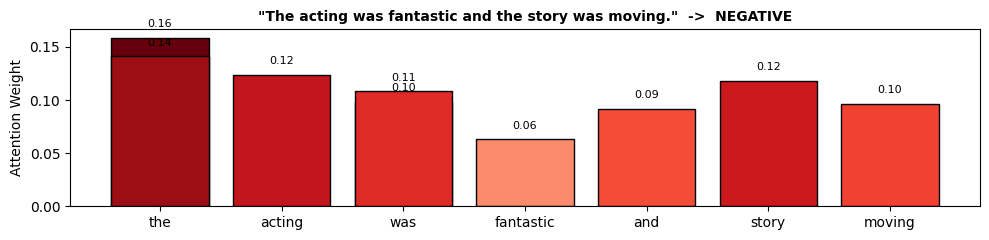


Sentence: "The plot was not good at all."
  Predicted: NEGATIVE  (confidence: 0.057)


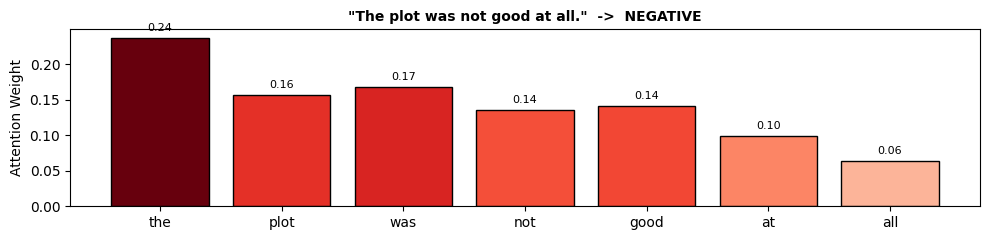


Sentence: "Oh great, another two hours wasted."
  Predicted: POSITIVE  (confidence: 0.604)


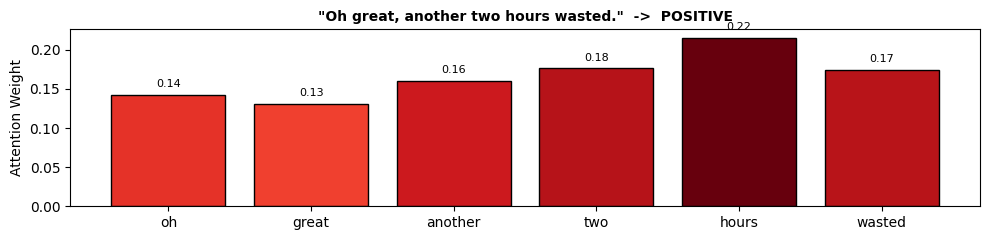


Sentence: "The visuals were stunning but the dialogue was dull."
  Predicted: NEGATIVE  (confidence: 0.031)


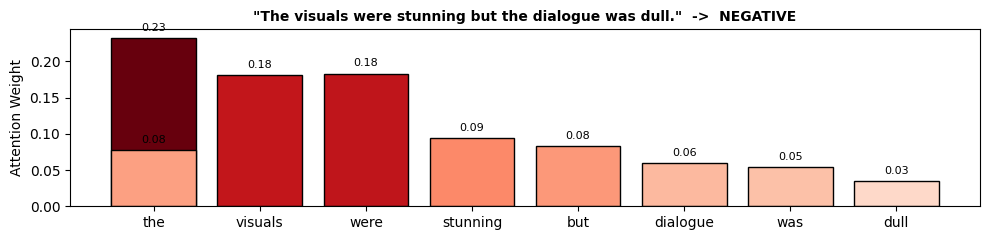


Sentence: "I did not dislike this film."
  Predicted: NEGATIVE  (confidence: 0.223)


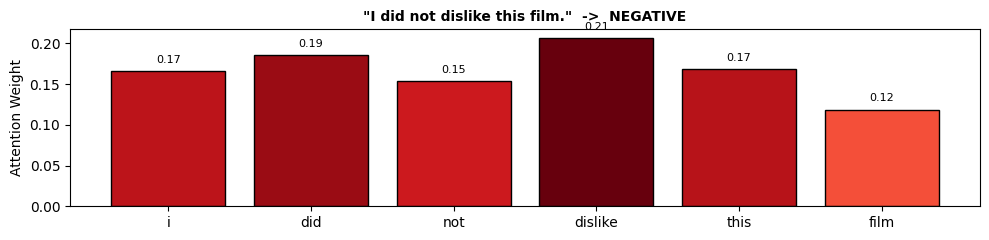


Plain SentimentLSTM (Day 3) test accuracy:      61.20%
AttentionSentimentLSTM (Day 4) test accuracy:    74.80%
Difference:                                      +13.60 pts


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# ============================================================
# STEP 1: Five review-style sentences we wrote ourselves,
# including at least 2 tricky structures (negation, sarcasm, mixed).
# ============================================================
test_sentences = [
    "The acting was fantastic and the story was moving.",
    "The plot was not good at all.",
    "Oh great, another two hours wasted.",
    "The visuals were stunning but the dialogue was dull.",
    "I did not dislike this film.",
]

attn_model.eval()

for sentence in test_sentences:
    # ---- STEP 2: run through AttentionSentimentLSTM ----
    words = simple_clean(sentence)
    seq   = text_to_sequence(sentence, max_len=len(words))   # no padding needed
    x     = torch.tensor([seq]).to(device)

    with torch.no_grad():
        output, attn_weights = attn_model(x)
        prob  = torch.sigmoid(output).item()
        label = "POSITIVE" if prob > 0.5 else "NEGATIVE"

    weights = attn_weights[0].cpu().numpy()[:len(words)]

    print(f"\nSentence: \"{sentence}\"")
    print(f"  Predicted: {label}  (confidence: {prob:.3f})")

    # bar chart, same style as Cell 36
    fig, ax = plt.subplots(figsize=(10, 2.5))
    colors = plt.cm.Reds(weights / weights.max())
    bars = ax.bar(words, weights, color=colors, edgecolor="black")
    ax.set_title(f'"{sentence}"  ->  {label}', fontsize=10, fontweight="bold")
    ax.set_ylabel("Attention Weight")
    for bar, w in zip(bars, weights):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f"{w:.2f}", ha="center", fontsize=8)
    plt.tight_layout()
    plt.show()

# ============================================================
# STEP 4: compare AttentionSentimentLSTM vs yesterday's plain
# SentimentLSTM on the real IMDB test set.
# ============================================================
plain_acc = evaluate_lstm(model, test_loader)
attn_acc  = evaluate_attn(attn_model, test_loader)

print("\n" + "="*55)
print(f"Plain SentimentLSTM (Day 3) test accuracy:      {plain_acc:.2%}")
print(f"AttentionSentimentLSTM (Day 4) test accuracy:    {attn_acc:.2%}")
print(f"Difference:                                      {(attn_acc - plain_acc)*100:+.2f} pts")


## Day 5 - Day 4 Extended

### Complete Reusable NLP Pipeline

In [ ]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))

def clean_text_pipeline(text):
    """Reusable text cleaning function -- built Day 1, works for ANY text task"""
    text   = text.lower()
    text   = re.sub(r"<br\s*/?>", " ", text)
    text   = re.sub(r"[^a-z\s]", "", text)
    tokens = [lemmatizer.lemmatize(w) for w in text.split()
              if w not in stop_words and len(w) > 2]
    return " ".join(tokens)

def train_text_classifier(texts, labels, test_size=0.2):
    """Reusable function: clean -> vectorize -> train -> evaluate"""
    cleaned = [clean_text_pipeline(t) for t in texts]

    vectorizer = TfidfVectorizer(max_features=3000, ngram_range=(1,2))
    X = vectorizer.fit_transform(cleaned)

    X_train, X_test, y_train, y_test = train_test_split(
        X, labels, test_size=test_size, random_state=42, stratify=labels
    )

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc   = accuracy_score(y_test, preds)

    return model, vectorizer, acc

print("Complete reusable NLP pipeline built!")
print("clean_text_pipeline() + train_text_classifier()")
print("can be reused for ANY text classification task by simply")
print("changing the input texts and labels.")

Complete reusable NLP pipeline built!
clean_text_pipeline() + train_text_classifier()
can be reused for ANY text classification task by simply
changing the input texts and labels.


### Using the Pipeline on IMDB

In [ ]:
from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")
sample_train = imdb["train"].shuffle(seed=42).select(range(3000))

texts  = [ex["text"] for ex in sample_train]
labels = [ex["label"] for ex in sample_train]

print("Training complete pipeline on IMDB reviews...")
model, vectorizer, accuracy = train_text_classifier(texts, labels)
print(f"\nFinal Accuracy: {accuracy:.2%}")

# Test on new, unseen sentences
test_sentences = [
    "This movie was absolutely fantastic, I loved every minute!",
    "Terrible acting and a boring plot, complete waste of time.",
    "The movie was not good at all, quite disappointing.",
    "I was not disappointed -- this was surprisingly excellent!",
]

cleaned_test = [clean_text_pipeline(s) for s in test_sentences]
X_test_new   = vectorizer.transform(cleaned_test)
predictions  = model.predict(X_test_new)
probabilities = model.predict_proba(X_test_new)

print(f"\nTesting on new sentences:")
for sentence, pred, prob in zip(test_sentences, predictions, probabilities):
    sentiment  = "Positive" if pred == 1 else "Negative"
    confidence = prob[pred]
    print(f"\n  '{sentence}'")
    print(f"  -> {sentiment} (confidence: {confidence:.1%})")

print(f"\nNotice the negation examples ('not good', 'not disappointed') --")
print(f"does the simple TF-IDF pipeline handle these correctly?")
print(f"This is exactly where LSTM/Attention (Day 3-4) can outperform")
print(f"simple bag-of-words style approaches.")

Training complete pipeline on IMDB reviews...

Final Accuracy: 84.17%

Testing on new sentences:

  'This movie was absolutely fantastic, I loved every minute!'
  -> Positive (confidence: 55.9%)

  'Terrible acting and a boring plot, complete waste of time.'
  -> Negative (confidence: 97.4%)

  'The movie was not good at all, quite disappointing.'
  -> Negative (confidence: 53.1%)

  'I was not disappointed -- this was surprisingly excellent!'
  -> Positive (confidence: 75.2%)

Notice the negation examples ('not good', 'not disappointed') --
does the simple TF-IDF pipeline handle these correctly?
This is exactly where LSTM/Attention (Day 3-4) can outperform
simple bag-of-words style approaches.


### Preview - HuggingFace Transformers

In [ ]:
print("EVERYTHING WE BUILT THIS WEEK, IN 3 LINES USING TRANSFORMERS")
print("="*55)

from transformers import pipeline

# This single line loads a pretrained Transformer model, already
# trained on MASSIVE amounts of text data (far more than we could
# ever process in a classroom)
sentiment_analyzer = pipeline("sentiment-analysis")

test_sentences = [
    "This movie was absolutely fantastic, I loved every minute!",
    "Terrible acting and a boring plot, complete waste of time.",
    "The movie was not good at all, quite disappointing.",
    "I was not disappointed -- this was surprisingly excellent!",
]

# Test on the SAME sentences from Cell 2
for sentence in test_sentences:
    result = sentiment_analyzer(sentence)[0]
    print(f"\n  '{sentence}'")
    print(f"  -> {result['label']} (confidence: {result['score']:.1%})")

print(f"""
COMPARE the results to our own TF-IDF pipeline above -- does the
Transformer handle the negation examples ("not good", "not
disappointed") more accurately?

WHY does Transformers do so well with just 3 lines of code?
  1. It uses SELF-ATTENTION (every word attends to every other
     word simultaneously) -- a more powerful version of Day 4's
     attention mechanism
  2. It was pretrained on BILLIONS of sentences -- similar to
     Week 5's transfer learning, but for TEXT instead of images
  3. The architecture has NO sequential bottleneck like our LSTM --
     it processes entire sentences in parallel

This is TRANSFER LEARNING FOR TEXT -- the exact same principle
from Week 5, Day 4, just applied to language instead of images.
Next week, we go deep into exactly how these Transformer models
work, and how to build real applications with them.
""")

EVERYTHING WE BUILT THIS WEEK, IN 3 LINES USING TRANSFORMERS


[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]


  'This movie was absolutely fantastic, I loved every minute!'
  -> POSITIVE (confidence: 100.0%)

  'Terrible acting and a boring plot, complete waste of time.'
  -> NEGATIVE (confidence: 100.0%)

  'The movie was not good at all, quite disappointing.'
  -> NEGATIVE (confidence: 100.0%)

  'I was not disappointed -- this was surprisingly excellent!'
  -> POSITIVE (confidence: 100.0%)

COMPARE the results to our own TF-IDF pipeline above -- does the
Transformer handle the negation examples ("not good", "not
disappointed") more accurately?

WHY does Transformers do so well with just 3 lines of code?
  1. It uses SELF-ATTENTION (every word attends to every other
     word simultaneously) -- a more powerful version of Day 4's
     attention mechanism
  2. It was pretrained on BILLIONS of sentences -- similar to
     Week 5's transfer learning, but for TEXT instead of images
  3. The architecture has NO sequential bottleneck like our LSTM --
     it processes entire sentences in parallel


### Save Your Custom Model

In [ ]:
import pickle

# Save both the vectorizer AND the model -- both are needed for prediction!
with open("sentiment_model.pkl", "wb") as f:
    pickle.dump({"model": model, "vectorizer": vectorizer}, f)
print("Model + vectorizer saved to sentiment_model.pkl")

# Simulate loading in a FRESH session (like a real deployment)
with open("sentiment_model.pkl", "rb") as f:
    loaded = pickle.load(f)

loaded_model      = loaded["model"]
loaded_vectorizer = loaded["vectorizer"]

def predict_sentiment(text, model, vectorizer):
    """Complete reusable prediction function -- ready for deployment"""
    cleaned  = clean_text_pipeline(text)
    features = vectorizer.transform([cleaned])
    pred     = model.predict(features)[0]
    prob     = model.predict_proba(features)[0][pred]
    return ("Positive" if pred == 1 else "Negative"), prob

# Test the loaded, deployed model
new_review = "What an incredible film, the cinematography was breathtaking!"
sentiment, confidence = predict_sentiment(new_review, loaded_model, loaded_vectorizer)
print(f"\nNew review: '{new_review}'")
print(f"Prediction: {sentiment} ({confidence:.1%} confidence)")
print(f"\nThis predict_sentiment() function is exactly what would power")
print(f"a real product feature -- e.g. auto-flagging negative reviews")
print(f"for a customer support team to review first.")

Model + vectorizer saved to sentiment_model.pkl

New review: 'What an incredible film, the cinematography was breathtaking!'
Prediction: Positive (70.3% confidence)

This predict_sentiment() function is exactly what would power
a real product feature -- e.g. auto-flagging negative reviews
for a customer support team to review first.


## Capstone Project

BUILD YOUR OWN COMPLETE TEXT CLASSIFICATION SYSTEM

Choose ONE task (or design your own):
  Option A: Classify news articles by topic (reuse Day 1's 20 Newsgroups)
  Option B: Sentiment analysis on a DIFFERENT text dataset you find
  Option C: Build a simple spam vs not-spam classifier

REQUIRED STEPS:

STEP 1: Data preparation
  Load your text data with labels
  Apply the complete clean_text_pipeline()

STEP 2: Model comparison
  Train BOTH: TF-IDF + Logistic Regression (Day 1 style)
             AND an LSTM (Day 3 style, if time permits)
  Compare accuracy and training time

STEP 3: Real-world testing
  Write 8 of your OWN test sentences (include tricky negation/
  sarcasm examples)
  Show predictions from your best model

STEP 4: HuggingFace comparison
  Run the SAME 8 sentences through pipeline("sentiment-analysis")
  or pipeline("zero-shot-classification") if doing topic classification
  Compare your model's predictions to the pretrained Transformer's

STEP 5: Save and deploy
  Save your best model
  Write a predict_sentiment() (or similar) function
  Demonstrate it working end-to-end

WRITTEN EXECUTIVE SUMMARY (5 sentences):
  What did you build? How does it perform? How did it compare to
  the pretrained Transformer? What would you improve next?

FINAL DELIVERABLE: Complete NLP Portfolio Project

REQUIRED SECTIONS:

1. PROBLEM STATEMENT:
   Choose a real-world text classification scenario
   (e.g. "classify customer support tickets by urgency")

2. DATA PIPELINE:
   Text data loaded, full cleaning pipeline applied,
   before/after examples shown

3. MODEL COMPARISON (at least 2 of the following):
   - TF-IDF + Logistic Regression / Naive Bayes
   - Word Embeddings + simple classifier
   - LSTM (with or without attention)
   Compare accuracy, training time, and handling of tricky examples

4. EVALUATION:
   Test on at least 10 of YOUR OWN written examples, including
   tricky cases (negation, sarcasm, mixed sentiment)
   Compare your best model's predictions to a HuggingFace
   pretrained pipeline on the SAME examples

5. DEPLOYMENT SIMULATION:
   Save your best model
   Write a prediction function
   Demonstrate it working on 3 brand-new examples

WRITTEN EXECUTIVE SUMMARY (5 sentences):
  As if presenting to a non-technical manager: what did you build,
  how well does it work, and would you recommend deploying it?

SUNDAY DEMO FORMAT (10 min each):
  "This week I built a text classifier for [task]. Here's how it
   works, how it compares to a pretrained model, and where it
   still struggles..."

# Week 2

Transformers Deep Dive + HuggingFace + LLM APIs + Prompt Engineering

## Day 1
The Transformer Architecture — Attention, Scaled Up

### Self-Attention From Scratch

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np

# Simplified self-attention -- see the QUERY/KEY/VALUE mechanism directly
torch.manual_seed(42)

seq_len, embed_dim = 6, 8   # 6 words, 8-dimensional embeddings
words = ["The", "animal", "crossed", "because", "it", "tired"]

# Random embeddings standing in for real learned word vectors
X = torch.randn(seq_len, embed_dim)

# In a real Transformer, these are LEARNED weight matrices
W_query = torch.randn(embed_dim, embed_dim) * 0.5
W_key   = torch.randn(embed_dim, embed_dim) * 0.5
W_value = torch.randn(embed_dim, embed_dim) * 0.5

# STEP 1: create Query, Key, Value versions of every word
Q = X @ W_query
K = X @ W_key
V = X @ W_value

print(f"Q, K, V shapes: {Q.shape} (each word gets its own Q, K, V vector)")

# STEP 2: compare every word's QUERY against every word's KEY
scores = Q @ K.T / np.sqrt(embed_dim)   # scaled dot-product
print(f"\nRaw attention scores shape: {scores.shape}")
print(f"(6x6 -- every word's relevance to every other word)")

# STEP 3: softmax -- convert to attention weights summing to 1 per row
attention_weights = F.softmax(scores, dim=-1)

print(f"\nAttention weights for the word 'it' (row 4):")
for word, weight in zip(words, attention_weights[4]):
    bar = "#" * int(weight * 50)
    print(f"  {word:<10}: {weight:.3f}  {bar}")

# STEP 4: weighted combination of all VALUE vectors
output = attention_weights @ V
print(f"\nFinal self-attention output shape: {output.shape}")
print(f"Every word now has a NEW representation, blended with")
print(f"context from every other word in the sentence.")

Q, K, V shapes: torch.Size([6, 8]) (each word gets its own Q, K, V vector)

Raw attention scores shape: torch.Size([6, 6])
(6x6 -- every word's relevance to every other word)

Attention weights for the word 'it' (row 4):
  The       : 0.783  #######################################
  animal    : 0.044  ##
  crossed   : 0.007  
  because   : 0.007  
  it        : 0.113  #####
  tired     : 0.046  ##

Final self-attention output shape: torch.Size([6, 8])
Every word now has a NEW representation, blended with
context from every other word in the sentence.


### Visualise Self-Attention as a Heatmap

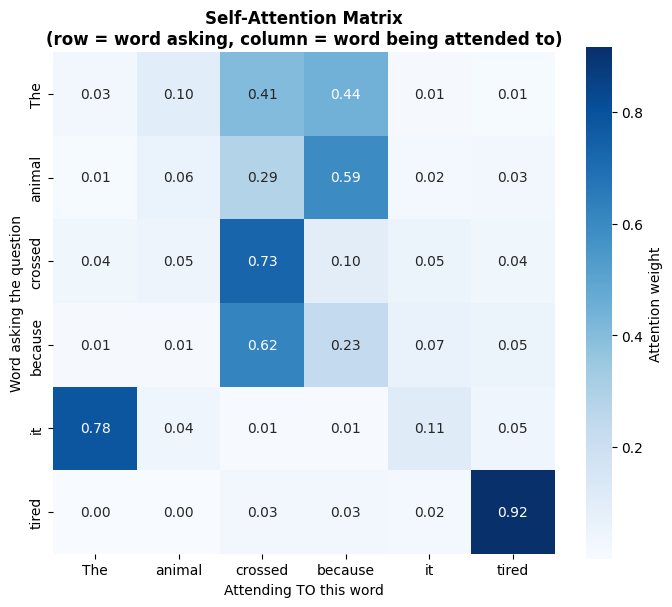

Read this heatmap ROW BY ROW:
Each row shows how much that word 'looks at' every other word.
A well-trained model would show 'it' -> row lighting up brightly
on 'animal' -- exactly the pronoun resolution we discussed.

This heatmap-of-attention is EXACTLY what researchers use to
peek inside GPT/Claude and understand what they're 'focusing on'
when generating each word of a response.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 6))
sns.heatmap(attention_weights.detach().numpy(),
           xticklabels=words, yticklabels=words,
           annot=True, fmt=".2f", cmap="Blues", square=True,
           cbar_kws={"label": "Attention weight"})
plt.title("Self-Attention Matrix\n(row = word asking, column = word being attended to)",
          fontweight="bold")
plt.xlabel("Attending TO this word")
plt.ylabel("Word asking the question")
plt.tight_layout(); plt.show()

print("Read this heatmap ROW BY ROW:")
print("Each row shows how much that word 'looks at' every other word.")
print("A well-trained model would show 'it' -> row lighting up brightly")
print("on 'animal' -- exactly the pronoun resolution we discussed.")
print("\nThis heatmap-of-attention is EXACTLY what researchers use to")
print("peek inside GPT/Claude and understand what they're 'focusing on'")
print("when generating each word of a response.")

####Multi head attention

In [ ]:
class MultiHeadAttention(torch.nn.Module):
    def __init__(self, embed_dim, num_heads):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads # split embedding across heads
        self.W_q = torch.nn.Linear(embed_dim, embed_dim)
        self.W_k = torch.nn.Linear(embed_dim, embed_dim)
        self.W_v = torch.nn.Linear(embed_dim, embed_dim)
        self.W_o = torch.nn.Linear(embed_dim, embed_dim) # combine heads back

    def forward(self, x):
      seq_len, embed_dim = x.shape

      Q = self.W_q(x).view(seq_len, self.num_heads, self.head_dim)
      K = self.W_k(x).view(seq_len, self.num_heads, self.head_dim)
      V = self.W_v(x).view(seq_len, self.num_heads, self.head_dim)

      # Move heads to the front so each head computes attention indepedndendently
      Q, K, V = Q.transpose(0, 1), K.transpose(0, 1), V.transpose(0, 1)

      scores = Q @ K.transpose(-2, -1) / np.sqrt(self.head_dim)
      weights = F.softmax(scores, dim=-1)
      head_outputs = weights @ V   #(num_heads, seq_len, head_dim)

      combined = head_outputs.transpose(0, 1).contiguous().view(seq_len, embed_dim)
      return self.W_o(combined), weights


mha = MultiHeadAttention(embed_dim=8, num_heads=4)
output, all_head_weights  = mha(X)

print(f"Input shape: {X.shape}")
print(f"Output shape: {output.shape}")
print(f"All head weights shape: {all_head_weights.shape}")

Input shape: torch.Size([6, 8])
Output shape: torch.Size([6, 8])
All head weights shape: torch.Size([4, 6, 6])


#### Positional Encoding

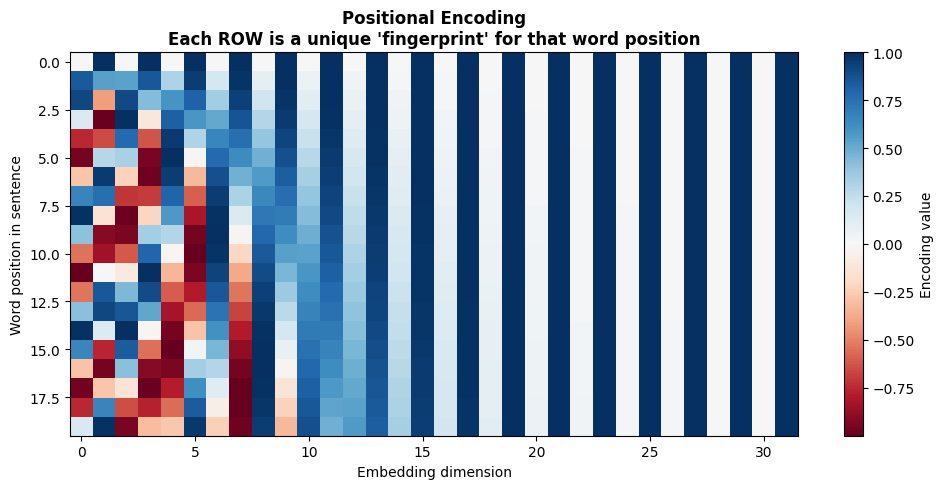

WHY sine and cosine waves specifically?
They create a UNIQUE pattern for every position, while also
having a mathematical property: the model can easily learn
RELATIVE positions ('3 words later') not just absolute ones.

This positional encoding gets ADDED directly to each word's
embedding BEFORE self-attention runs -- giving the model a
sense of order despite processing all words simultaneously.


In [ ]:
def positional_encoding(seq_len, embed_dim):
  """The mathematical 'seat number badge' for each word position"""
  positions = np.arange(seq_len)[:, np.newaxis]
  dim       = np.arange(embed_dim)[np.newaxis, :]

  angle_rates = 1 / np.power(10000, (2 * (dim // 2)) / embed_dim)
  angles      = positions * angle_rates

  pos_encoding = np.zeros((seq_len, embed_dim))
  pos_encoding[:, 0 ::2] = np.sin(angles[:, 0::2])  #even dimensions: sine
  pos_encoding[:, 1::2]  = np.cos(angles[:, 1::2])  #odd dimensions: cosine
  return pos_encoding
pe  = positional_encoding(seq_len=20, embed_dim=32)
plt.figure(figsize=(10, 5))
plt.imshow(pe, cmap="RdBu", aspect="auto")
plt.colorbar(label="Encoding value")
plt.xlabel("Embedding dimension")
plt.ylabel("Word position in sentence")
plt.title("Positional Encoding\nEach ROW is a unique 'fingerprint' for that word position",
         fontweight="bold")
plt.tight_layout(); plt.show()

print("WHY sine and cosine waves specifically?")
print("They create a UNIQUE pattern for every position, while also")
print("having a mathematical property: the model can easily learn")
print("RELATIVE positions ('3 words later') not just absolute ones.")
print("\nThis positional encoding gets ADDED directly to each word's")
print("embedding BEFORE self-attention runs -- giving the model a")
print("sense of order despite processing all words simultaneously.")

In [ ]:
from transformers import pipeline

print("Loading pretrained sentiment analysis model...")
sentiment_analyzer = pipeline("sentiment-analysis")

reviews = [
  "This laptop exceeded all my expectations, absolutely fantastic build quality",
  "Terrible customer service, my order arrived damaged and nobody responded.",
  "It's okay I guess does the job but nothing special.",

]

print("\nSENTIMENT ANALYSIS RESULTS:")
for review in reviews:
  result = sentiment_analyzer(review)[0]
  print(f"\n '{review}'")
  print(f" -> {result['label']} (confidence: {result['score']:.1%}")


# ZERO - SHOT CLASSIFICATION - classify into ANY  categories, no training needed
print("\n"+ "="*55)
print("ZERO-SHOT CLASSIFICATION -- custom categories no retraining")
print("="*55)

classifier = pipeline("zero-shot-classification")

text = "The new iPhone features a titanium frame and improved camera system"
candidate_labels = ["technology","sports","politics","cooking","finance"]

result = classifier(text, candidate_labels)
print(f"\nText: '{text}'")
print(f"/nCategory probabilites")
for label, score in zip(result["labels"], result["scores"]):
  bar = "#" * int(score*40)
  print(f" {label:<12}: {score:.1%} {bar}")


print(f"\nNOTICE: we never trained this model on 'technology' or 'sports'")
print(f"as specific categories! zero-shot classification works by")
print(f"compari the TEXT's meaning to ach labels meaning using")
print(f"the same semantic understanding we explored with word")
print(f"embeddings in week 6")

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading pretrained sentiment analysis model...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


SENTIMENT ANALYSIS RESULTS:

 'This laptop exceeded all my expectations, absolutely fantastic build quality'
 -> POSITIVE (confidence: 100.0%


[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.



 'Terrible customer service, my order arrived damaged and nobody responded.'
 -> NEGATIVE (confidence: 100.0%

 'It's okay I guess does the job but nothing special.'
 -> NEGATIVE (confidence: 99.1%

ZERO-SHOT CLASSIFICATION -- custom categories no retraining


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]


Text: 'The new iPhone features a titanium frame and improved camera system'
/nCategory probabilites
 technology  : 96.2% ######################################
 sports      : 2.0% 
 finance     : 1.1% 
 politics    : 0.4% 
 cooking     : 0.3% 

NOTICE: we never trained this model on 'technology' or 'sports'
as specific categories! zero-shot classification works by
compari the TEXT's meaning to ach labels meaning using
the same semantic understanding we explored with word
embeddings in week 6


####Text summarization

In [ ]:
print("Loading pretrained summarization model>>>")
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

tokenizer = AutoTokenizer.from_pretrained("facebook/bart-large-cnn")
model = AutoModelForSeq2SeqLM.from_pretrained("facebook/bart-large-cnn")

def summarize(text, max_length=60, min_length = 20):
  inputs = tokenizer(text, return_tensors ="pt", max_length = 1024, truncation = True)
  summary_ids = model.generate(inputs["input_ids"], max_length = max_length, min_length = min_length, do_sample = False)
  return tokenizer.decode(summary_ids[0], skip_special_tokens = True)

long_article = """
Machine learning is a method of data analysis that automates analytical
model building. It is a branch of artificial intelligence based on the
idea that systems can learn from data, identify patterns and make
decisions with minimal human intervention. Machine learning algorithms
are trained using large sets of data, and they learn from experience,
without being explicitly programmed. As the algorithms ingest training
data, it becomes possible to produce more precise models based on that
data. A machine learning model is the output generated when you train
your machine learning algorithm with data. After training, when you
provide a model with an input, you will be given an output. For example,
a predictive algorithm will create a predictive model. Then, when you
provide the predictive model with data, you will receive a prediction
based on the data that trained the model.
"""

summary_text = summarize(long_article)

print(f"Original length: {len(long_article.split())} words")
print(f"Summary: {summary_text}")
print(f"Summary length: {len(summary_text.split())} words")

print(f"\nThis model was trained on CNN/DailyMail news articles to")
print(f"learn how professional editors compress long articles into")
print(f"short summaries -- we're reusing that learned skill here.")

Loading pretrained summarization model>>>


config.json:   0%|          | 0.00/1.58k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

Original length: 141 words
Summary: Machine learning is a branch of artificial intelligence based on the idea that systems can learn from data. Machine learning algorithms are trained using large sets of data, and they learn from experience.
Summary length: 33 words

This model was trained on CNN/DailyMail news articles to
learn how professional editors compress long articles into
short summaries -- we're reusing that learned skill here.


####Question Answering


In [ ]:
print("Loadng Question Answering model....")
from transformers import AutoTokenizer, AutoModelForQuestionAnswering

import torch
qa_tokenizer = AutoTokenizer.from_pretrained("distilbert-base-cased-distilled-squad")
qa_model = AutoModelForQuestionAnswering.from_pretrained("distilbert-base-cased-distilled-squad")


def answer_question(question, context):
  inputs = qa_tokenizer(question, context, return_tensors ="pt")

  with torch.no_grad():
    outputs = qa_model(**inputs)

  start_scores = outputs.start_logits
  end_scores = outputs.end_logits

  start_idx = torch.argmax(start_scores)
  end_idx = torch.argmax(end_scores) + 1

  answer_tokens = inputs["input_ids"][0][start_idx:end_idx]
  answer = qa_tokenizer.decode(answer_tokens, skip_special_tokens=True)

  # confidence = how strongly the model favoures thi exact start\end position
  start_prob = torch.softmax(start_scores, dim =1)[0][start_idx].item()
  end_prob = torch.softmax(end_scores, dim =1)[0][end_idx-1].item()
  confidence = (start_prob + end_prob) / 2

  return answer, confidence

  # Confidence = how strongly the model favoired this exact start/end position
  start_prob = torch.softmax(start_scores, dim=1)[0][start_idx].item()
  end_prob = torch.softmax(end_scores, dim=1)[0][end_idx - 1].item()
  confidence = (start_prob + end_prob) / 2

  return answer, confidence

context = """
The Eiffel Tower is a wrought-iron lattice tower on the Champ de Mars
in Paris, France. It is named after the engineer Gustave Eiffel, whose
company designed and built the tower. Constructed from 1887 to 1889,
it was initially criticized by some of France's leading artists and
intellectuals for its design, but it has become a global cultural icon
of France. The tower is 330 metres tall and was the tallest man-made
structure in the world for 41 years, until the Chrysler Building in
New York City was finished in 1930.
"""

questions = [
    "Who designed the Eiffel Tower?",
    "How tall is the Eiffel Tower?",
    "When was it built?",
    "What building surpassed it in height?",
]

print(f"Context: (Eiffel Tower Wikipedia excerpt)\n")
for question in questions:
    answer, confidence = answer_question(question, context)
    print(f"Q: {question}")
    print(f"A: {answer}  (confidence: {confidence:.1%})\n")

print("This model READS the context and EXTRACTS the exact answer span --")
print("it doesn't generate new text, it finds and highlights the")
print("relevant part of the provided context. This is called")
print("'extractive' question answering.")

Loadng Question Answering model....


model.safetensors: reconstructing file:   0%|          |  0.00B /  261MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Context: (Eiffel Tower Wikipedia excerpt)

Q: Who designed the Eiffel Tower?
A: Gustave Eiffel  (confidence: 99.5%)

Q: How tall is the Eiffel Tower?
A: 330 metres  (confidence: 79.7%)

Q: When was it built?
A: 1887 to 1889  (confidence: 80.8%)

Q: What building surpassed it in height?
A:   (confidence: 53.4%)

This model READS the context and EXTRACTS the exact answer span --
it doesn't generate new text, it finds and highlights the
relevant part of the provided context. This is called
'extractive' question answering.


####Named Entity Recognition

In [ ]:
print("Loading Named Entity Recognition (NER) model...")

ner = pipeline("ner", aggregation_strategy="simple")

text = "Tim Cook announced that Apple will open a new headquarters in Austin, Texas next year, generating $50 million in local investment."

entities = ner(text)

print(f"Text: {text}\n")
print("Entities found:")

for entity in entities:
    print(
        f"  {entity['word']:<20} - {entity['entity_group']:<8} "
        f"(confidence: {entity['score']:.1%})"
    )

print("""
ENTITY TYPES:
PER  = Person          (Tim Cook)
ORG  = Organization    (Apple)
LOC  = Location        (Austin, Texas)
MISC = Miscellaneous   (other named things)

NER is used constantly in real products: extracting company names
from news for financial analysis, extracting locations from
customer support tickets for regional routing, extracting person
names from legal documents for redaction.
""")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading Named Entity Recognition (NER) model...


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

Text: Tim Cook announced that Apple will open a new headquarters in Austin, Texas next year, generating $50 million in local investment.

Entities found:
  Tim Cook             - PER      (confidence: 99.9%)
  Apple                - ORG      (confidence: 99.8%)
  Austin               - LOC      (confidence: 99.9%)
  Texas                - LOC      (confidence: 100.0%)

ENTITY TYPES:
PER  = Person          (Tim Cook)
ORG  = Organization    (Apple)
LOC  = Location        (Austin, Texas)
MISC = Miscellaneous   (other named things)

NER is used constantly in real products: extracting company names
from news for financial analysis, extracting locations from
customer support tickets for regional routing, extracting person
names from legal documents for redaction.



###Day 3

#### Your first LLM API CALL

In [1]:
from google.colab import userdata
#Install if needed: pip install groq
try:
  from groq import Groq
except ImportError:
  import subprocess; subprocess.run(["pip","install","groq","-q"])
  from groq import Groq

GROQ_API_KEY = userdata.get("kaustubh_aiml")

client = Groq(api_key=GROQ_API_KEY)

response = client.chat.completions.create(
    model = "openai/gpt-oss-20b",
    messages = [
        {"role": "user","content":"Explain what machine learning is in 2 sentences."}
    ]
)

print("LLM Responses:")
print(response.choices[0].message.content)

print(f"\n-- Token usage (this is what you're billed for on paid APIs) --")
print(f"Prompt tokens:  {response.usage.prompt_tokens}")
print(f"Completion tokens: {response.usage.completion_tokens}")
print(f"Total tokens:    {response.usage.total_tokens}")

LLM Responses:
Machine learning is a branch of artificial intelligence that enables computers to learn patterns and make predictions from data without being explicitly programmed for each task. By iteratively adjusting internal models based on input-output examples, these systems improve their performance over time across a wide range of applications.

-- Token usage (this is what you're billed for on paid APIs) --
Prompt tokens:  81
Completion tokens: 94
Total tokens:    175


#### System prompt

In [2]:
def ask_llm(user_message, system_message="You are a helpful assistant."):
  """Reusable """
  response = client.chat.completions.create(
      model = "openai/gpt-oss-20b",
      messages = [
          {"role": "system", "content": system_message},
          {"role": "user", "content": user_message}
      ]
  )
  return response.choices[0].message.content

# Same Question, Different system prompts -- watch the persona change!

question = "what is overfitting in machine learning in 2 sentences ?"

print("--- Persona 1: Expert Data Science Professor ---")
answer1 = ask_llm(question,
                  system_message = "You are a PhD professor of machine learning."
                  "Use precise technical terminology.")
print(answer1)


print("--- Persona 2: Explaining to a 5-Year-Old ---")
answer2 = ask_llm(question,
                  system_message = "You explain complex topics to a 5-year-old child"
                  "Using simple analogies and no technical jargon")
print(answer2)


print("--- Persona 3: Sarcastic Comedian ---")
answer3= ask_llm(question,
                system_message = "You are a sarcastic stand-up comedian who explains"
                  "things with humor ans wit.")
print(answer3)


print(f"\nSame question, SAME model, SAME underlying knowledge --")
print(f"but the SYSTEM prompt completly changes tone, complexity")
print(f"and style. This is the foundation of 'prompt engineering',")
print(f"which we go deep on tomorrow")

--- Persona 1: Expert Data Science Professor ---
Overfitting occurs when a model captures idiosyncratic noise in the training set, thereby reducing empirical risk while inflating expected risk on unseen data. This manifests as a divergence between training and test performance, typically because the model’s capacity exceeds the true complexity of the data‑generating process.
--- Persona 2: Explaining to a 5-Year-Old ---
Imagine a kid who only ever sees the same picture of a dog and then says, “Every time I see anything, it must be that exact dog,” even if the picture is a cat or a rabbit. Overfitting is like that—when a learning machine remembers only the few things it was shown, instead of learning the true shape of all dogs, so it gets wrong when it sees new pictures.
--- Persona 3: Sarcastic Comedian ---
Overfitting is when your model becomes a parrot: it can recite every training example perfectly but screams at anything else that even looks similar. It's like a student who memoriz

####Temperature in Practice

In [3]:
def ask_with_temperature(prompt, temperature):
    response = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[{"role": "user", "content": prompt}],
        temperature=temperature,
        max_tokens=60
    )

    return response.choices[0].message.content


prompt = "Write a one-sentence tagline for a new coffee shop."

print("SAME prompt, DIFFERENT temperatures -- run 3 times each:\n")

for temp in [0.0, 0.7, 1.3]:
    print(f"--- Temperature = {temp} ---")

    for i in range(3):
        result = ask_with_temperature(prompt, temp)
        print(f"  {i+1}. {result}")

    print()


print("At temperature=0.0, notice the outputs are IDENTICAL or nearly")
print("identical every time -- fully deterministic.")

print("At temperature=1.3, notice much more VARIETY and creativity,")
print("but potentially less coherent or on-topic results.")

print("\nWHEN TO USE WHICH:")
print("  temp=0.0-0.3: factual Q&A, code generation, data extraction")
print("  temp=0.7:     general conversation, balanced creativity (default)")
print("  temp=1.0+:    creative writing, brainstorming, poetry")

SAME prompt, DIFFERENT temperatures -- run 3 times each:

--- Temperature = 0.0 ---
  1. "Awaken your day with the perfect blend of bold flavor and cozy vibes."
  2. "Awaken your day with the perfect blend of bold flavor and cozy vibes."
  3. "Awaken your day with the perfect blend of bold flavor and cozy vibes."

--- Temperature = 0.7 ---
  1. "Awaken your day, one perfect sip at a time."
  2. "Fuel your day with bold brews and cozy vibes—where every cup feels like a warm hug."
  3. "Awaken your day with the perfect blend of bold flavor and cozy vibes."

--- Temperature = 1.3 ---
  1. "Bold brews, bright mornings—where every cup sparks a fresh start."
  2. "Awaken Your Day, One Perfect Brew at a Time."
  3. "Awaken your day, one perfectly brewed moment at a time."

At temperature=0.0, notice the outputs are IDENTICAL or nearly
identical every time -- fully deterministic.
At temperature=1.3, notice much more VARIETY and creativity,
but potentially less coherent or on-topic results.

WH

####Multi-turn Conversation

In [4]:
print("Multi-TURN CONVERSATION  -- How Chat Memory Actually Works")
print("-"*55)
print("""
IMPORTANT: LLMs have NO memory between API calls by default!
Every single request is completely independent -- the model has
No idea what you asked 2 minutes ago UNLESS you explicitly send
the ENTIRE conversation history with every new request.

ChatGPT/Claude's web interfaces do this automatically behind the
scenes -- they resend your whole conversation history every time
you send a new message. Let's build this manually to see how it works.""")

conversation_history = [
    {"role": "system", "content": "You are a helpful data science tutor."}
]

def chat(user_message):
    conversation_history.append({"role": "user", "content": user_message})

    response = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=conversation_history
    )

    assistant_reply = response.choices[0].message.content
    conversation_history.append({"role": "assistant", "content": assistant_reply})
    return assistant_reply


# Turn 1
print("User: What is a neural network?")
print(f"AI: {chat('What is a neural network?')}\n")


# Turn 2 — referring back to the previous answer!
print("User: Can you give me a simple example of one?")
print(f"AI: {chat('Can you give me a simple example of one?')}\n")


# Turn 3 — testing if it remembers context
print("User: What was my first question?")
print(f"AI: {chat('What was my first question?')}\n")


print(f"Conversation history now has {len(conversation_history)} messages.")
print(f"EVERY message in this list gets resent with each new API call ——")
print(f"this is literally how 'memory' works in chat applications.")
print("\nNOTE: Longer conversations = more tokens spent")
print(f"and eventually you'll hut the model's maximum content length!")

Multi-TURN CONVERSATION  -- How Chat Memory Actually Works
-------------------------------------------------------

IMPORTANT: LLMs have NO memory between API calls by default!
Every single request is completely independent -- the model has
No idea what you asked 2 minutes ago UNLESS you explicitly send
the ENTIRE conversation history with every new request.

ChatGPT/Claude's web interfaces do this automatically behind the
scenes -- they resend your whole conversation history every time
you send a new message. Let's build this manually to see how it works.
User: What is a neural network?
AI: ### Neural Networks – A Beginner‑Friendly Overview  

A **neural network** (NN) is a type of **machine‑learning model** inspired by the way biological brains process information. At its core, it’s a flexible function‑approximator that can learn complex patterns from data by adjusting internal parameters (weights) through a process called **training**.

Below is a step‑by‑step breakdown of the key i

###Day 4

####Promp Engineering -- The Art and Science of Asking Well

#### Zero-Shot vs Few-Shot

In [5]:
def ask_llm(prompt, temperature=0.3):
  response = client.chat.completions.create(
      model="openai/gpt-oss-120b",
      messages=[{"role": "user","content":prompt}],
      temperature=temperature
  )
  return response.choices[0].message.content

review = "The delivery was late but the product quality exceeded my expectations."

#Level 1: Zero-Shot
zero_shot_prompt = f"""Classify this review as Positive, Negative, or Neutral:
"{review}"
Classification:"""

print("--- Zero-Shot ---")
print(ask_llm(zero_shot_prompt))

#Level 2: Few-Shot
few_shot_prompt = f"""Classify reviews as Positive, Negative, or Neutral.

Review: "This is the best product I've ever bought!"
Classification: Positive

Review: "Complete waste of money, broke after one day."
Classification: Negative

Review: "It's oaky, nothing special."
Classification: Neutral

Now classify:
Review: "{review}"
Classification: """

print("\n--- Few-Shot ---")
print(ask_llm(few_shot_prompt))

print(f"\nWith mixed-sentiment reviews like this one, few-shot examples")
print(f"often produce MORE consistent, better-calibrated classifications")
print(f"because the model has a clear pattern of the expected format")
print(f"and reasoning style to follow.")

--- Zero-Shot ---
Positive

--- Few-Shot ---
Classification: Positive

With mixed-sentiment reviews like this one, few-shot examples
often produce MORE consistent, better-calibrated classifications
because the model has a clear pattern of the expected format
and reasoning style to follow.


####Chain of thoughtS

In [6]:
#A genuinely trickt reasoning problem
math_problem = "A store had 120 apples. They sold 35% of them in the morning" \
              "and 28 more in the afternoon. How many apples are left?"

#Without chain-of-though
direct_prompt = f"{math_problem}\nAnswer:"
print("-- Direct (no reasoning shown) ---")
print(ask_llm(direct_prompt, temperature=0))

#With chain-of-thought
cot_prompt = f"""{math_problem}

Lets solve this step by step:
1. First, Calculate how many apples were sold in the morning
2. Then, subtract the afternoon sales
3. State the final answer clearly

Step-by=step solution:"""

print("\n--- CHAIN-OF-THOUGHT ---")
print(ask_llm(cot_prompt, temperature=0))
print(f"\nFor problems requiring MULTIPLE steps of reasoning, explicity")
print(f"asking the model to show its work often IMPROVES accuracy ---")
print(f"the model 'thinks out loud', catching potential errors along")
print(f"the way, rather than jumping straight to a possibly-wrong answer.")
print(f"\nThis technique is genuinely used in production systems for")
print(f"complex reasoning tasks: legal analysis, financial calculations,")
print(f"multi-step data extraction.")

-- Direct (no reasoning shown) ---
The store sold  

- 35 % of 120 apples = 0.35 × 120 = **42** apples in the morning,  
- plus **28** apples in the afternoon.

Total apples sold = 42 + 28 = **70**.

Apples remaining = 120 − 70 = **50**.

**Answer: 50 apples are left.**

--- CHAIN-OF-THOUGHT ---
**Step 1 – Apples sold in the morning**  
35 % of 120 apples = 0.35 × 120 = **42 apples**.

**Step 2 – Apples sold in the afternoon**  
The store sold an additional 28 apples.

**Step 3 – Total apples sold and apples left**  
Total sold = 42 (morning) + 28 (afternoon) = **70 apples**.  

Apples remaining = 120 (original) – 70 (sold) = **50 apples**.

**Answer:** The store has **50 apples left**.

For problems requiring MULTIPLE steps of reasoning, explicity
asking the model to show its work often IMPROVES accuracy ---
the model 'thinks out loud', catching potential errors along
the way, rather than jumping straight to a possibly-wrong answer.

This technique is genuinely used in production syst

####Structured output (JSON)

In [7]:
import json

structured_prompt = """Analyze this customer review and respond ONLY
with valid JSON in exactly this format, no other text:

{
  "sentiment" : "Positive" or "Negative" or "Neutral"
  "confidence" : a number between 0.0 and 1.0
  "key_phrases": a list of up to 3 important phrases from the review,
  "requires_response": true or false (does this need a company reply?)
}

Review: "The delivery was late but the product quality exceeded my
expectations. I'm still a bit annoyed about the shipping delay though."
"""

response = ask_llm(structured_prompt, temperature=0)
print("Raw LLM response:")
print(response)

#Try to parse it as a real JSON -- this is what makes it USABLE in code
try:
  #clean up common formatting issues (models sometimes add markdown backticks)
  cleaned = response.strip().strip("```json").strip("```").strip()
  parsed = json.loads(cleaned)
  print(f"\nSuccesfully parsed as Python dictionary!")
  print(f"  Sentiment:  {parsed["sentiment"]}")
  print(f"  Confidence: {parsed["confidence"]}")
  print(f"  Key phrases:  {parsed["key_phrases"]}")
  print(f"  Needs responses:  {parsed["requires_response"]}")
except json.JSONDecodeError as e:
  print(f"\nJSON parsing failed:  {e}")
  print(f"(This happens sometimes == production systems need error)")
  print(f"handling and retry logic for reliable JSON formatting")

print(f"\nWHY THIS MATTERS: structured output is what lets tou connect")
print(f"an LLM's response DIRECTLY into your Python code --  storing")
print(f"results in a database, triggering automated actions, feeding")
print(f"into dashboards -- without a human reading and re-typing anything.")

Raw LLM response:
{
  "sentiment": "Neutral",
  "confidence": 0.78,
  "key_phrases": [
    "delivery was late",
    "product quality exceeded my expectations",
    "annoyed about the shipping delay"
  ],
  "requires_response": true
}

Succesfully parsed as Python dictionary!
  Sentiment:  Neutral
  Confidence: 0.78
  Key phrases:  ['delivery was late', 'product quality exceeded my expectations', 'annoyed about the shipping delay']
  Needs responses:  True

WHY THIS MATTERS: structured output is what lets tou connect
an LLM's response DIRECTLY into your Python code --  storing
results in a database, triggering automated actions, feeding
into dashboards -- without a human reading and re-typing anything.


####Reusable Prompt Templates

In [10]:
class PromptTemplate:
  """A resuable, parameterised prompt - avoids repeating yourself"""
  def __init__(self, template):
    self.template = template

  def format(self, **kwargs):
    return self.template.format(**kwargs)


# Build a genuinely reusable template for any teaching topic
explain_template = PromptTemplate("""
You are an expert {subject} teacher.
Explain {topic} to a {level} student.
Give exactly {num_points} key points.
Use one simple real-world analogy.
Keep your total response under {max_words} words.
""")

prompt1 = explain_template.format(
    subject ="data science", topic = "overfitting",
    level ="complete begineer", num_points = 3, max_words = 100
)

print("-- Generated Prompt 1 ---")
print(prompt1)

print("\n-- LLM RESPONSE --")
print(ask_llm(prompt1))

prompt2 = explain_template.format(
    subject = "machine learning", topic = "gradient descent",
  level = "intermediate", num_points = 4, max_words = 150
)

print("\n\m--Generated Prompt 2(reusing the SAME template) ---")
print(ask_llm(prompt2))


print(f"\nThis is the FOUNDATION of production LLM applciation")
print(f"instead of hand-writting every prompt, you buid TEMPALTES")
print(f"with variables, and generate hundreds of tailored prompts")
print(f"programmatically. This pattern scales from 1 question to")
print(f"1 million questions with the same underlying code.")

<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_164/833413776.py:35: SyntaxWarning: invalid escape sequence '\m'
  print("\n\m--Generated Prompt 2(reusing the SAME template) ---")


-- Generated Prompt 1 ---

You are an expert data science teacher.
Explain overfitting to a complete begineer student.
Give exactly 3 key points.
Use one simple real-world analogy.
Keep your total response under 100 words.


-- LLM RESPONSE --
Overfitting happens when a model learns the training data too well, including its noise, and fails on new data.

**Key points**  
1. It captures random quirks, not the underlying pattern.  
2. Performance looks great on training data but drops on unseen data.  
3. Simpler models or more data can reduce overfitting.

**Analogy** – Like a student who memorizes every answer from last year’s test instead of understanding the subject; they ace that test but struggle on a new one.

\m--Generated Prompt 2(reusing the SAME template) ---
Gradient descent is an optimization algorithm that iteratively adjusts parameters to minimize a loss function.  

**Key points**  
1. Compute the gradient (slope) of the loss w.r.t. each parameter; it points uphill.  
2. 

#### Capstone